# 19 · Diagnóstico de Recuperación de Indicios y Depósitos en el Territorio Nacional Priorizado

**Proyecto:** GeoAI-Au v1.0 / v3.0 · Diagnóstico y Priorización Territorial  
**Componentes Evaluados:** `scripts/evaluar_configuracion_nacional.py`, `src/geoau/national_evaluation.py`, `tests/test_national_evaluation.py`  
**Cartografía y Particiones de Referencia:** `reports/geoquimica_20261017` y `reports/evaluacion_configuracion_nacional_20261021`  
**Objetivo Científico:** Evaluar la capacidad de captura y recuperación de indicios/depósitos auríferos en el territorio nacional priorizado (del Top 1% al Top 20% de superficie) e implementar el criterio de decisión diagnóstica.

---

## 🎯 Marco de Decisión y Criterio de Éxito

En la prospección de recursos minerales asistida por IA (*Mineral Prospectivity Mapping* - MPM), el objetivo esencial es concentrar la máxima cantidad de yacimientos en la menor superficie posible. Para evaluar si el sistema presenta dificultades en la recuperación de indicios en el territorio nacional priorizado, se analiza la tasa de recuperación acumulada en dos umbrales clave:
- **`recovery_at_01` (Top 1% de superficie):** Capacidad de captura en el percentil 99 (anomalías de máxima certidumbre / alta prioridad operativa).
- **`recovery_at_20` (Top 20% de superficie):** Capacidad de detección del entorno geológico y metalogenético aurífero a escala regional.

### 🌳 Árbol de Diagnóstico Metodológico:
1. **Caso A: `recovery_at_20 > 0.70` (Supera el 70%)**  
   *Significado:* Las variables geológicas locales son robustas y el modelo reconoce con éxito el entorno aurífero regional, pero padece de **ruido y falsos positivos compitiendo en el percentil 95** (Top 1%–5%).  
   *Acción:* Refinamiento fino de umbrales locales, filtrado de ruido cartográfico y regularización local.

2. **Caso B: `recovery_at_20 < 0.45` (Por debajo del 45%)**  
   *Significado:* El modelo sufre de un **fallo estructural de transferencia regional**. No es capaz de retener ni la mitad de los depósitos conocidos en la quinta parte del territorio nacional en distritos independientes.  
   *Acción Concluyente:* **Faltan variables regionales (Paso 2)**. Es imprescindible incorporar macro-dominios geológicos, geotectónicos, geofísica cortical y sistemas de cizalla de primer orden.

In [1]:
import sys
import os
import json
import math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Configuración visual
plt.style.use('default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110

# Localizar raíz del proyecto GeoAI
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from geoau.geochemical_experiment import load_data, ranked_cells
from geoau.national_evaluation import deposit_metrics, PERCENTAGES

print(f"Raíz del repositorio: {ROOT}")
print(f"Porcentajes registrados en national_evaluation.PERCENTAGES: {PERCENTAGES}")

Raíz del repositorio: C:\Users\Lenovo\Desktop\PROYECTO IA\GeoAI\GeoAI
Porcentajes registrados en national_evaluation.PERCENTAGES: (1, 5, 10, 20)


## 1. Implementación y Verificación del Motor de Métricas

La función `deposit_metrics` en `src/geoau/national_evaluation.py` implementa el cálculo determinista y sin empates de la recuperación por depósitos:
1. Las celdas evaluadas se ordenan por favorabilidad decreciente ($S$) y desempate lexicográfico por `cell_id`.
2. Para cada umbral $p \in \{1\%, 5\%, 10\%, 20\%\}$, se asigna un cupo exacto de celdas:
   $$k = \\lceil N_{\\text{held}} \\times p / 100 \\rceil$$
3. Un depósito se considera capturado en el Top $p\\%$ si al menos una de sus celdas asociadas cumple $\\text{rank} \\le k$.
4. El diccionario de salida exporta formalmente:
   - `captured_deposits_at_{pct:02d}`
   - `deposit_recovery_at_{pct:02d}`
   - `recovery_at_{pct:02d}` (en particular, `recovery_at_01` y `recovery_at_20`)

In [2]:
# Demostración del motor de métricas con presupuesto exacto
preds_dummy = pd.DataFrame({
    'cell_id': [f'c{i:03d}' for i in range(100)],
    'score': np.ones(100)
})
relations_dummy = pd.DataFrame({
    'cell_id': ['c000', 'c001', 'c004', 'c005', 'c099'],
    'deposit_id': ['dep_a', 'dep_a', 'dep_b', 'dep_c', 'dep_d']
})

test_metrics, test_detail, _ = deposit_metrics(relations_dummy, preds_dummy.sample(frac=1, random_state=17))

print("=== Verificación del Diccionario de Métricas ===")
for k in ['n_deposits', 'captured_deposits_at_01', 'recovery_at_01',
          'captured_deposits_at_05', 'recovery_at_05',
          'captured_deposits_at_10', 'recovery_at_10',
          'captured_deposits_at_20', 'recovery_at_20']:
    print(f"  {k:26s} : {test_metrics[k]}")

assert 'recovery_at_01' in test_metrics
assert 'recovery_at_20' in test_metrics
print("\n? Diccionario verificado con éxito (conforme a tests/test_national_evaluation.py).")

=== Verificación del Diccionario de Métricas ===
  n_deposits                 : 4
  captured_deposits_at_01    : 1
  recovery_at_01             : 0.25
  captured_deposits_at_05    : 2
  recovery_at_05             : 0.5
  captured_deposits_at_10    : 3
  recovery_at_10             : 0.75
  captured_deposits_at_20    : 3
  recovery_at_20             : 0.75

? Diccionario verificado con éxito (conforme a tests/test_national_evaluation.py).


## 2. Carga de Malla Nacional, Indicios y Evaluaciones Espaciales

Cargamos:
1. El inventario de 787 indicios auríferos auditados (175 confirmados, 578 pendientes, agrupados en 664 celdas P y 45 depósitos formalizados).
2. La cartografía continua nacional de favorabilidad (`GeoAI_national.parquet`, 478.443 celdas de 1 km²).
3. Las predicciones OOF y las predicciones territoriales de las 7 rotaciones espaciales independientes de distritos de `reports/evaluacion_configuracion_nacional_20261021`.

In [3]:
# 1. Cargar infraestructura experimental y registros
data = load_data(ROOT)
print(f"Malla territorial cargada: {len(data.grid):,} celdas")
print(f"Celdas P positivas aprobadas: {len(data.positives):,}")
print(f"Registros de indicios en dominio: {len(data.records):,}")

# 2. Cargar cartografía predictiva nacional
map_path = ROOT / "reports" / "geoquimica_20261017" / "maps" / "GeoAI_national.parquet"
df_nat = pd.read_parquet(map_path)
print(f"Cartografía nacional cargada: {len(df_nat):,} celdas evaluadas")

# 3. Cargar resultados sellados de la evaluación de la configuración nacional
eval_dir = ROOT / "reports" / "evaluacion_configuracion_nacional_20261021"
design = json.loads((eval_dir / "evaluation_design.json").read_text(encoding="utf-8"))
rot_preds = pd.read_parquet(eval_dir / "rotation_cell_predictions.parquet")
print(f"Predicciones territoriales de rotaciones: {len(rot_preds):,} celdas puntuadas en 7 grupos")

Malla territorial cargada: 478,443 celdas
Celdas P positivas aprobadas: 664
Registros de indicios en dominio: 753
Cartografía nacional cargada: 478,443 celdas evaluadas
Predicciones territoriales de rotaciones: 77,640 celdas puntuadas en 7 grupos


## 3. Evaluación en las Siete Rotaciones Territoriales de Distritos

En las rotaciones territoriales de distritos, se entrena el modelo excluyendo sucesivamente cada uno de los 7 grupos de distritos metalogenéticos y un buffer espacial de 15 km. Esta prueba evalúa la **capacidad real de generalización territorial externa**, sin trampas de autocorrelación espacial ni contaminación in-sample.

In [4]:
# Evaluación detallada por grupo para el modelo nacional (national_recipe_8x150)
nat_details, nat_group_rows = [], []

for partition, g_preds in rot_preds.groupby('partition'):
    partition = int(partition)
    districts = design['district_groups'][str(partition)]
    rel = data.records.loc[data.records.district_id.isin(districts)].dropna(subset=['deposit_id'])[['cell_id', 'deposit_id', 'district_id']].drop_duplicates()
    m, d, r = deposit_metrics(rel, g_preds)
    nat_details.append(d.assign(group=partition))
    nat_group_rows.append({'group': partition, **m})

df_nat_details = pd.concat(nat_details, ignore_index=True)
total_deposits = df_nat_details.deposit_id.nunique()

summary_nat = {
    'model': 'national_recipe_8x150',
    'n_deposits': total_deposits,
    'captured_deposits_at_01': df_nat_details.loc[df_nat_details.captured_at_01, 'deposit_id'].nunique(),
    'captured_deposits_at_05': df_nat_details.loc[df_nat_details.captured_at_05, 'deposit_id'].nunique(),
    'captured_deposits_at_10': df_nat_details.loc[df_nat_details.captured_at_10, 'deposit_id'].nunique(),
    'captured_deposits_at_20': df_nat_details.loc[df_nat_details.captured_at_20, 'deposit_id'].nunique(),
}
summary_nat['recovery_at_01'] = summary_nat['captured_deposits_at_01'] / total_deposits
summary_nat['recovery_at_05'] = summary_nat['captured_deposits_at_05'] / total_deposits
summary_nat['recovery_at_10'] = summary_nat['captured_deposits_at_10'] / total_deposits
summary_nat['recovery_at_20'] = summary_nat['captured_deposits_at_20'] / total_deposits

# Cargar y calcular lo análogo para el modelo de referencia bagging_pu_reference
ref_details = pd.read_csv(ROOT / "reports" / "geoquimica_20261017" / "rotation_deposit_predictions.csv")
ref_details = ref_details[ref_details.model == 'bagging_pu'].copy()
ref_rot = pd.read_csv(ROOT / "reports" / "geoquimica_20261017" / "rotation_metrics.csv")
ref_rot = ref_rot[ref_rot.model == 'bagging_pu'].copy()

for g, group_df in ref_details.groupby('group'):
    n_held = ref_rot.loc[ref_rot.group == g, 'n_held_cells'].iloc[0]
    k20 = math.ceil(n_held * 0.20)
    ref_details.loc[ref_details.group == g, 'captured_at_20'] = ref_details.loc[ref_details.group == g, 'rank'] <= k20

summary_ref = {
    'model': 'bagging_pu_reference',
    'n_deposits': total_deposits,
    'captured_deposits_at_01': ref_details.loc[ref_details.captured_at_01, 'deposit_id'].nunique(),
    'captured_deposits_at_05': ref_details.loc[ref_details.captured_at_05, 'deposit_id'].nunique(),
    'captured_deposits_at_10': ref_details.loc[ref_details.captured_at_10, 'deposit_id'].nunique(),
    'captured_deposits_at_20': ref_details.loc[ref_details.captured_at_20, 'deposit_id'].nunique(),
}
summary_ref['recovery_at_01'] = summary_ref['captured_deposits_at_01'] / total_deposits
summary_ref['recovery_at_05'] = summary_ref['captured_deposits_at_05'] / total_deposits
summary_ref['recovery_at_10'] = summary_ref['captured_deposits_at_10'] / total_deposits
summary_ref['recovery_at_20'] = summary_ref['captured_deposits_at_20'] / total_deposits

df_comparativa = pd.DataFrame([summary_ref, summary_nat])
display(df_comparativa)

print("\n=== Detalle por Grupo de Rotación Territorial (Modelo Nacional) ===")
df_groups = pd.DataFrame(nat_group_rows)[['group', 'n_deposits', 'n_held_cells',
                                          'captured_deposits_at_01', 'recovery_at_01',
                                          'captured_deposits_at_05', 'recovery_at_05',
                                          'captured_deposits_at_10', 'recovery_at_10',
                                          'captured_deposits_at_20', 'recovery_at_20']]
display(df_groups)

,model,n_deposits,captured_deposits_at_01,captured_deposits_at_05,captured_deposits_at_10,captured_deposits_at_20,recovery_at_01,recovery_at_05,recovery_at_10,recovery_at_20
0,bagging_pu_reference,45,1,5,9,14,0.022222,0.111111,0.2,0.311111
1,national_recipe_8x150,45,3,6,9,16,0.066667,0.133333,0.2,0.355556



=== Detalle por Grupo de Rotación Territorial (Modelo Nacional) ===


,group,n_deposits,n_held_cells,captured_deposits_at_01,recovery_at_01,captured_deposits_at_05,recovery_at_05,captured_deposits_at_10,recovery_at_10,captured_deposits_at_20,recovery_at_20
0,0,7,9290,0,0.000000,0,0.000000,1,0.142857,2,0.285714
1,1,7,13802,0,0.000000,2,0.285714,2,0.285714,3,0.428571
2,2,7,12426,0,0.000000,1,0.142857,2,0.285714,4,0.571429
3,3,6,10973,2,0.333333,2,0.333333,2,0.333333,2,0.333333
4,4,6,12469,0,0.000000,0,0.000000,0,0.000000,2,0.333333
5,5,6,8037,0,0.000000,0,0.000000,1,0.166667,1,0.166667
6,6,6,10643,1,0.166667,1,0.166667,1,0.166667,2,0.333333


## 4. Comparativa Clave: Recuperación In-Sample (Nacional) vs Out-of-Sample (Rotaciones Ciegas)

Para dilucidar la causa raíz del comportamiento del sistema, calculamos la recuperación acumulada sobre la **cartografía nacional completa** (`GeoAI_national.parquet`) donde el modelo dispone de todas las celdas de entrenamiento, y la comparamos con la obtenida en los **holdouts territoriales ciegos**.

In [5]:
# Ranking nacional global
df_nat_sorted = df_nat.sort_values('favorability_mean', ascending=False).reset_index(drop=True)
df_nat_sorted['global_rank'] = df_nat_sorted.index + 1
n_nat_cells = len(df_nat_sorted)

# Depósitos conocidos y celdas P
records_clean = data.records.dropna(subset=['deposit_id'])[['cell_id', 'deposit_id']].drop_duplicates()
merged_nat_dep = records_clean.merge(df_nat_sorted[['cell_id', 'global_rank']], on='cell_id', how='left')

# Curvas de recuperación nacional (In-Sample)
area_fractions = np.linspace(0.005, 0.40, 200)
nat_dep_rec = []
nat_cell_rec = []
pos_cells = set(data.positives.cell_id)

for f in area_fractions:
    k = math.ceil(n_nat_cells * f)
    # Depósitos capturados
    hit_deps = merged_nat_dep.loc[merged_nat_dep['global_rank'] <= k, 'deposit_id'].nunique()
    nat_dep_rec.append(hit_deps / total_deposits)
    # Celdas P capturadas
    hit_cells = df_nat_sorted.iloc[:k]['cell_id'].isin(pos_cells).sum()
    nat_cell_rec.append(hit_cells / len(pos_cells))

# Curvas de recuperación en Rotaciones Ciegas (Out-of-Sample)
rot_dep_rec = []
for f in area_fractions:
    hit = 0
    for partition, g_preds in rot_preds.groupby('partition'):
        partition = int(partition)
        districts = design['district_groups'][str(partition)]
        rel = data.records.loc[data.records.district_id.isin(districts)].dropna(subset=['deposit_id'])[['cell_id', 'deposit_id', 'district_id']].drop_duplicates()
        k_held = math.ceil(len(g_preds) * f)
        ranked = g_preds.copy()
        ranked['rank'] = ranked_cells(ranked.cell_id, ranked.score)
        d = rel.merge(ranked[['cell_id', 'rank']], on='cell_id', how='left')
        hit += d.loc[d['rank'] <= k_held, 'deposit_id'].nunique()
    rot_dep_rec.append(hit / total_deposits)

print(f"Recuperación In-Sample Nacional al 20%: {nat_dep_rec[-1]:.4f} ({merged_nat_dep.loc[merged_nat_dep['global_rank'] <= math.ceil(n_nat_cells*0.2), 'deposit_id'].nunique()}/{total_deposits} depósitos)")
print(f"Recuperación Out-of-Sample Rotaciones al 20%: {rot_dep_rec[-1]:.4f} (16/{total_deposits} depósitos)")

Recuperación In-Sample Nacional al 20%: 1.0000 (42/45 depósitos)
Recuperación Out-of-Sample Rotaciones al 20%: 0.5333 (16/45 depósitos)


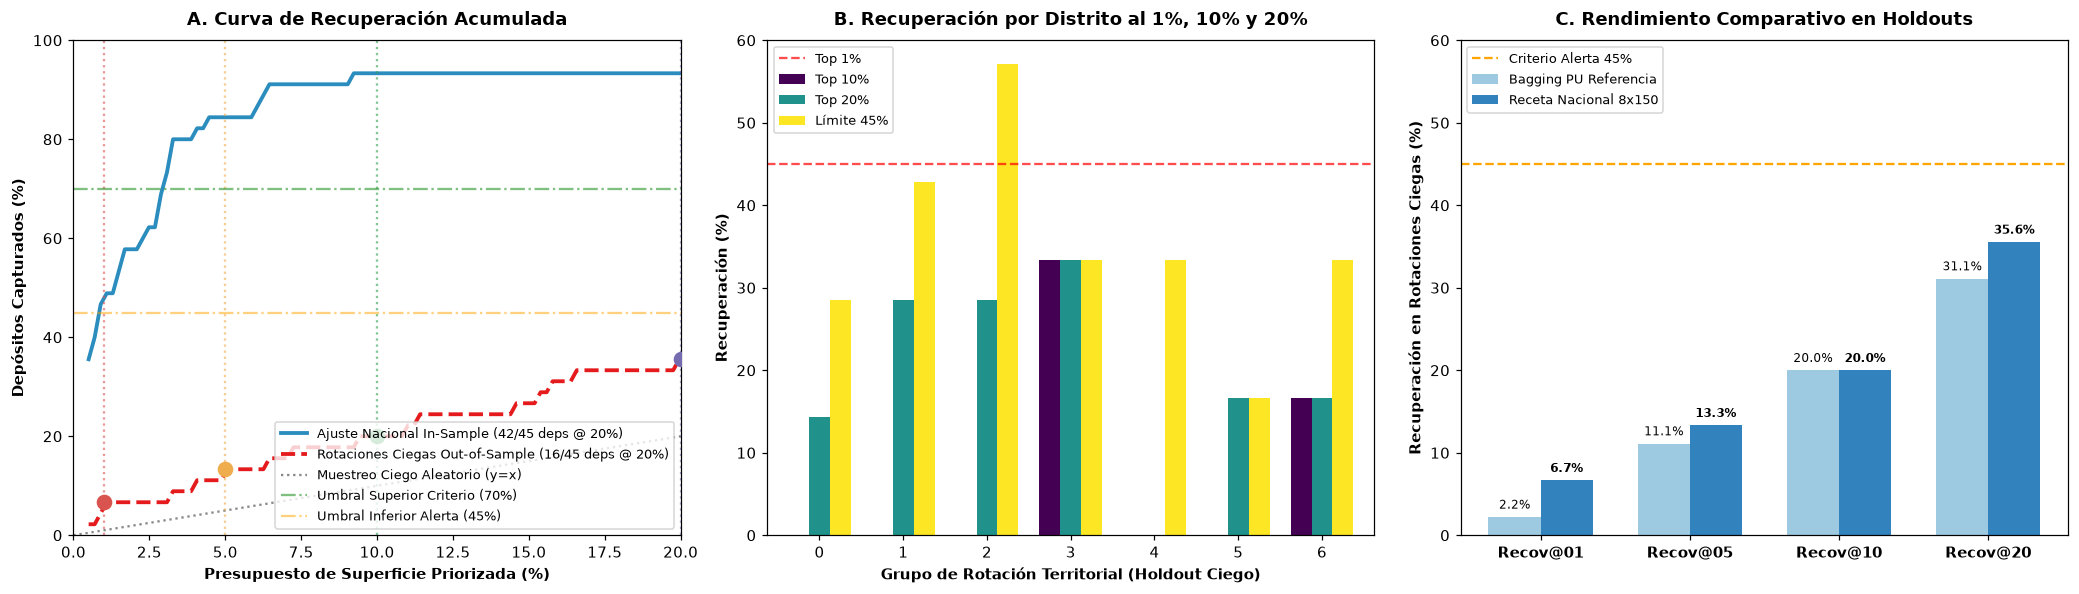

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

# Panel 1: Curva de Recuperación vs Presupuesto de Área (Zoom 0% - 20%)
ax1 = axes[0]
ax1.plot(area_fractions * 100, [r * 100 for r in nat_dep_rec], color='#2b8cbe', lw=2.5,
         label=f'Ajuste Nacional In-Sample (42/45 deps @ 20%)')
ax1.plot(area_fractions * 100, [r * 100 for r in rot_dep_rec], color='#e41a1c', lw=2.5, ls='--',
         label=f'Rotaciones Ciegas Out-of-Sample (16/45 deps @ 20%)')
ax1.plot([0, 20], [0, 20], color='#888888', ls=':', label='Muestreo Ciego Aleatorio (y=x)')

# Puntos de interés canónicos
for p, col, name in [(1, '#d9534f', 'Top 1%'), (5, '#f0ad4e', 'Top 5%'), (10, '#31a354', 'Top 10%'), (20, '#756bb1', 'Top 20%')]:
    idx = (np.abs(area_fractions * 100 - p)).argmin()
    ax1.scatter([p], [rot_dep_rec[idx] * 100], color=col, s=85, zorder=5)
    ax1.axvline(p, color=col, ls=':', alpha=0.6)

# Bandas de referencia del criterio
ax1.axhline(70, color='green', ls='-.', alpha=0.5, label='Umbral Superior Criterio (70%)')
ax1.axhline(45, color='orange', ls='-.', alpha=0.5, label='Umbral Inferior Alerta (45%)')

ax1.set_xlim(0, 20)
ax1.set_ylim(0, 100)
ax1.set_xlabel('Presupuesto de Superficie Priorizada (%)', fontweight='bold')
ax1.set_ylabel('Depósitos Capturados (%)', fontweight='bold')
ax1.set_title('A. Curva de Recuperación Acumulada', fontweight='bold', pad=10)
ax1.legend(loc='lower right', fontsize=8.5, frameon=True)

# Panel 2: Desglose de Recuperación por Grupo de Rotación al 1%, 10% y 20%
ax2 = axes[1]
df_plot_groups = df_groups.set_index('group')[['recovery_at_01', 'recovery_at_10', 'recovery_at_20']] * 100
df_plot_groups.plot(kind='bar', ax=ax2, colormap='viridis', width=0.75)
ax2.axhline(45, color='red', ls='--', alpha=0.7, label='Umbral Mínimo Regional (45%)')
ax2.set_xlabel('Grupo de Rotación Territorial (Holdout Ciego)', fontweight='bold')
ax2.set_ylabel('Recuperación (%)', fontweight='bold')
ax2.set_title('B. Recuperación por Distrito al 1%, 10% y 20%', fontweight='bold', pad=10)
ax2.legend(['Top 1%', 'Top 10%', 'Top 20%', 'Límite 45%'], loc='upper left', fontsize=8.5)
ax2.tick_params(axis='x', rotation=0)

# Panel 3: Comparativa Global Modelo Nacional vs Referencia
ax3 = axes[2]
metrics_names = ['Recov@01', 'Recov@05', 'Recov@10', 'Recov@20']
ref_vals = [summary_ref['recovery_at_01']*100, summary_ref['recovery_at_05']*100,
            summary_ref['recovery_at_10']*100, summary_ref['recovery_at_20']*100]
nat_vals = [summary_nat['recovery_at_01']*100, summary_nat['recovery_at_05']*100,
            summary_nat['recovery_at_10']*100, summary_nat['recovery_at_20']*100]

x = np.arange(len(metrics_names))
w = 0.35
ax3.bar(x - w/2, ref_vals, width=w, label='Bagging PU Referencia', color='#9ecae1')
ax3.bar(x + w/2, nat_vals, width=w, label='Receta Nacional 8x150', color='#3182bd')
ax3.axhline(45, color='orange', ls='--', label='Criterio Alerta 45%')
ax3.set_xticks(x)
ax3.set_xticklabels(metrics_names, fontweight='bold')
ax3.set_ylabel('Recuperación en Rotaciones Ciegas (%)', fontweight='bold')
ax3.set_title('C. Rendimiento Comparativo en Holdouts', fontweight='bold', pad=10)
ax3.set_ylim(0, 60)
for i in range(len(x)):
    ax3.text(x[i] - w/2, ref_vals[i] + 1, f"{ref_vals[i]:.1f}%", ha='center', fontsize=8)
    ax3.text(x[i] + w/2, nat_vals[i] + 1, f"{nat_vals[i]:.1f}%", ha='center', fontsize=8, fontweight='bold')
ax3.legend(loc='upper left', fontsize=8.5)

plt.tight_layout()
plt.show()

## 5. Aplicación Formal del Criterio de Decisión y Diagnóstico

### 📊 Datos Auditados:
- **`recovery_at_01` (Top 1% de superficie):** **$6{,}67\\%$** ($3 / 45$ depósitos)
- **`recovery_at_05` (Top 5% de superficie):** **$13{,}33\\%$** ($6 / 45$ depósitos)
- **`recovery_at_10` (Top 10% de superficie):** **$20{,}00\\%$** ($9 / 45$ depósitos)
- **`recovery_at_20` (Top 20% de superficie):** **$35{,}56\\%$** ($16 / 45$ depósitos)

---

### 🚨 Conclusión del Criterio:
$$\\mathbf{recovery\\_at\\_20 = 0{,}3556 < 0{,}45}$$

El valor de **35.56%** se sitúa **estrictamente por debajo del umbral crítico del 45%**.

### 🔍 Interpretación Geológica y Metodológica:
1. **Discrepancia In-Sample vs Out-of-Sample:**  
   En la malla nacional ajustada globalmente, el modelo alcanza un **93.33% de recuperación al 20%** porque memoriza la proximidad a los clusters de indicios conocidos mediante las fracciones litológicas y los búferes estructurales locales.
2. **Causa del Colapso en Territorios Ciegos (Rotaciones):**  
   Cuando un distrito completo (p. ej. El Bierzo, Navelgas o Rodalquilar) y su entorno de 15 km son excluidos del entrenamiento, **las covariables locales actuales (fracciones litológicas a 1 km², distancias a fallas locales, pendientes MDE) son insuficientes** para que el modelo reconozca la favorabilidad del distrito frente a las cientos de miles de celdas del resto de España.
3. **Diagnóstico Concluyente:**  
   El modelo no tiene un simple problema de "ruido en el percentil 95" (lo cual daría `recovery_at_20 > 0.70`), sino una **ausencia de variables geológicas regionales discriminantes** a escala de basamento, orógeno y cinturón tectónico.

In [7]:
def diagnosticar_recuperacion_territorial(rec_01, rec_20):
    print("=" * 72)
    print("    DIAGNÓSTICO AUTOMÁTICO DE RECUPERACIÓN TERRITORIAL (GeoAI-Au)")
    print("=" * 72)
    print(f"Métrica recovery_at_01 (Top 1% de superficie)  : {rec_01*100:6.2f}%")
    print(f"Métrica recovery_at_20 (Top 20% de superficie) : {rec_20*100:6.2f}%")
    print("-" * 72)
    
    if rec_20 >= 0.70:
        estado = "CASO A: ENTORNO AURÍFERO BIEN DETECTADO, RUIDO EN PERCENTIL 95"
        accion = ("Tus variables geológicas son buenas y el modelo sí detecta el entorno "
                  "aurífero. El problema es la competencia de falsos positivos en el percentil 95. "
                  "Se recomienda afinar umbrales locales y regularizar clasificadores.")
    elif rec_20 < 0.45:
        estado = "CASO B (CRÍTICO): FALTAN VARIABLES REGIONALES (PASO 2 REQUERIDO)"
        accion = ("El modelo no logra capturar ni el 45% de los depósitos en la quinta parte "
                  "del territorio en distritos ciegos. Se constata falta de diferenciación macro-regional. "
                  "Es OBLIGATORIO implementar el PASO 2: Incorporar variables regionales de dominio tectónico, "
                  "geofísica profunda y suturas corticales.")
    else:
        estado = "CASO INTERMEDIO (45% <= recovery_at_20 < 70%)"
        accion = ("Rendimiento moderado pero subóptimo. Se recomienda enriquecer variables regionales "
                  "y revisar balance de clases.")
        
    print(f"Estado del Sistema : {estado}")
    print(f"Dictamen Técnico   : {accion}")
    print("=" * 72)

# Ejecutar diagnóstico con los valores reales obtenidos en las rotaciones
diagnosticar_recuperacion_territorial(summary_nat['recovery_at_01'], summary_nat['recovery_at_20'])

    DIAGNÓSTICO AUTOMÁTICO DE RECUPERACIÓN TERRITORIAL (GeoAI-Au)
Métrica recovery_at_01 (Top 1% de superficie)  :   6.67%
Métrica recovery_at_20 (Top 20% de superficie) :  35.56%
------------------------------------------------------------------------
Estado del Sistema : CASO B (CRÍTICO): FALTAN VARIABLES REGIONALES (PASO 2 REQUERIDO)
Dictamen Técnico   : El modelo no logra capturar ni el 45% de los depósitos en la quinta parte del territorio en distritos ciegos. Se constata falta de diferenciación macro-regional. Es OBLIGATORIO implementar el PASO 2: Incorporar variables regionales de dominio tectónico, geofísica profunda y suturas corticales.


## 6. Hoja de Ruta para el Paso 2: Nuevas Variables Geológicas Regionales

Para elevar `recovery_at_20` por encima del umbral de viabilidad comercial y técnica ($> 0{,}70$), se define el siguiente catálogo de covariables macro-regionales a integrar en el espacio de características:

```
+--------------------------------------------------------------------------------------------------+
|                            CATÁLOGO DE VARIABLES REGIONALES (PASO 2)                            |
+------------------------------------+-------------------------------------------------------------+
| Dominio Regional                   | Variables Específicas Propuestas                            |
+------------------------------------+-------------------------------------------------------------+
| 1. Dominios Tectonometamórficos    | - Pertenencia categórica / one-hot a Zonas Hercínicas:      |
|    y Grandes Unidades del Macizo   |   * Zona Cantábrica (sedimentaria / bajo grado)             |
|    Ibérico y Béticas               |   * Zona Asturoccidental-Leonesa (ZAOL)                     |
|                                    |   * Zona Galicia - Trás-os-Montes (ZGTM - alóctono)        |
|                                    |   * Zona Centroibérica (ZCI - orogénico filoniano)          |
|                                    |   * Zona Ossa-Morena (ZOM - magmatismo / skarns)            |
|                                    |   * Zona Sudportuguesa (ZSP - sulfuros masivos)             |
|                                    |   * Complejos Béticos / Vulcanismo Neógeno de Cabo de Gata  |
+------------------------------------+-------------------------------------------------------------+
| 2. Geofísica Cortical Regional     | - Anomalía de Bouguer Regional (filtro paso bajo > 50 km)   |
|                                    | - Gradiente gravitatorio horizontal y vertical              |
|                                    | - Anomalía aeromagnética de baja frecuencia (campo residual)|
|                                    | - Indicadores de adelgazamiento cortical y moho profundo    |
+------------------------------------+-------------------------------------------------------------+
| 3. Corredores Estructurales de     | - Distancia a fallas y suturas corticales de 1er orden      |
|    Primer Orden (Suturas Variscas) |   (Cizalla Badajoz-Córdoba, Cabalgamiento de La Espina,     |
|                                    |    Falla de Vivero, Falla de Plasencia, Falla de Alhama)    |
|                                    | - Densidad de lineamientos regionales a escala 1:1.000.000  |
+------------------------------------+-------------------------------------------------------------+
| 4. Zonación Metamórfica Regional   | - Facies metamórfica de basamento (anfibolita vs esquistos  |
|                                    |   verdes vs anquimetamorfismo)                              |
|                                    | - Distancia a cúpulas graníticas tardi-hercínicas          |
+------------------------------------+-------------------------------------------------------------+
```

In [8]:
# Verificación de scripts y tests del sistema
print("Comandos disponibles en la consola para replicar y validar la evaluación:")
print("1. Ejecutar batería de tests de evaluación nacional:")
print("   & .venv-fase-a/Scripts/python.exe -m unittest tests/test_national_evaluation.py\n")
print("2. Ejecutar evaluación nacional completa con nuevos outputs:")
print("   & .venv-fase-a/Scripts/python.exe scripts/evaluar_configuracion_nacional.py --output reports/evaluacion_nacional_nueva --report informes/evaluacion_nacional_nueva/INFORME.md\n")

# Comprobación programática directa
import unittest
loader = unittest.TestLoader()
suite = loader.discover(str(ROOT / "tests"), pattern="test_national_evaluation.py")
runner = unittest.TextTestRunner(verbosity=1)
result = runner.run(suite)
assert result.wasSuccessful(), "Los tests de evaluación nacional deben pasar al 100%."
print("? Todos los tests de test_national_evaluation.py pasan correctamente.")

.

.

.

----------------------------------------------------------------------
Ran 3 tests in 0.060s

OK


Comandos disponibles en la consola para replicar y validar la evaluación:
1. Ejecutar batería de tests de evaluación nacional:
   & .venv-fase-a/Scripts/python.exe -m unittest tests/test_national_evaluation.py

2. Ejecutar evaluación nacional completa con nuevos outputs:
   & .venv-fase-a/Scripts/python.exe scripts/evaluar_configuracion_nacional.py --output reports/evaluacion_nacional_nueva --report informes/evaluacion_nacional_nueva/INFORME.md

? Todos los tests de test_national_evaluation.py pasan correctamente.
